# 코드 C · 주가 일기장 — 포트폴리오 시계열 읽기
**핀테크 데이터 분석 : 실제로 해보는 데이터 분석편 #01**  
원본: [fintech-data/Revolution3](https://github.com/fintech-data/Revolution3) `Loading_Data.ipynb` → 이 폴더의 `original_Loading_Data.ipynb`  
해설 페이지: https://adminmrobo.github.io/fintech_data_analysis/hands_on_01.html

> 코드를 몰라도 괜찮아요. 위에서부터 ▶ 실행 버튼만 차례로 누르면 됩니다.

## 이 코드가 하는 일
날짜별 종가(그날 마지막 가격)를 적은 **주가 일기장** 두 권(미국 4종목, 한·미 국제 지표)을 불러옵니다. 원본에 없던 세 번째 일기장(`new_portfolio_data.csv`)도 함께 열어 봅니다.

> 비유: 매일 저녁 몸무게를 적은 다이어리. 한 줄이 하루입니다.

In [1]:
import os, io, urllib.request
import pandas as pd
pd.set_option('display.max_columns', 12); pd.set_option('display.width', 120)

# 데이터 위치: 이 폴더의 data/ 에 있으면 그걸 쓰고, 없으면(Colab 등) GitHub에서 바로 읽습니다.
RAW = 'https://raw.githubusercontent.com/adminmrobo/fintech_data_analysis/main/hands_on/01/C_portfolio_price_diary/data/'
def load(name, **kw):
    local = os.path.join('data', name)
    src = local if os.path.exists(local) else RAW + urllib.parse.quote(name)
    return pd.read_csv(src, low_memory=False, **kw)
print('준비 완료')

준비 완료


In [2]:
portfolio_data = load('portfolio_data.csv')
print(portfolio_data.shape, portfolio_data['Date'].iloc[0], '→', portfolio_data['Date'].iloc[-1])
portfolio_data.head()

(1520, 5) 5/1/2013 → 5/14/2019


,Date,AMZN,DPZ,BTC,NFLX
0,5/1/2013,248.229996,51.190983,106.250000,30.415714
1,5/2/2013,252.550003,51.987320,98.099998,30.641428
2,5/3/2013,258.049988,52.446388,112.900002,30.492857
3,5/6/2013,255.720001,53.205257,109.599998,30.098572
4,5/7/2013,257.730011,54.151505,113.199997,29.464285


In [3]:
prices = portfolio_data.set_index(pd.to_datetime(portfolio_data['Date']))[['AMZN', 'DPZ', 'BTC', 'NFLX']]
print('처음 대비 마지막 값(배):'); print((prices.iloc[-1] / prices.iloc[0]).round(1))
print('하루 수익률의 표준편차(%) — 흔들림의 크기:'); print((prices.pct_change().std() * 100).round(2))

처음 대비 마지막 값(배):
AMZN     7.4
DPZ      5.3
BTC     77.0
NFLX    11.4
dtype: float64
하루 수익률의 표준편차(%) — 흔들림의 크기:
AMZN     1.90
DPZ      1.58
BTC     10.46
NFLX     2.67
dtype: float64


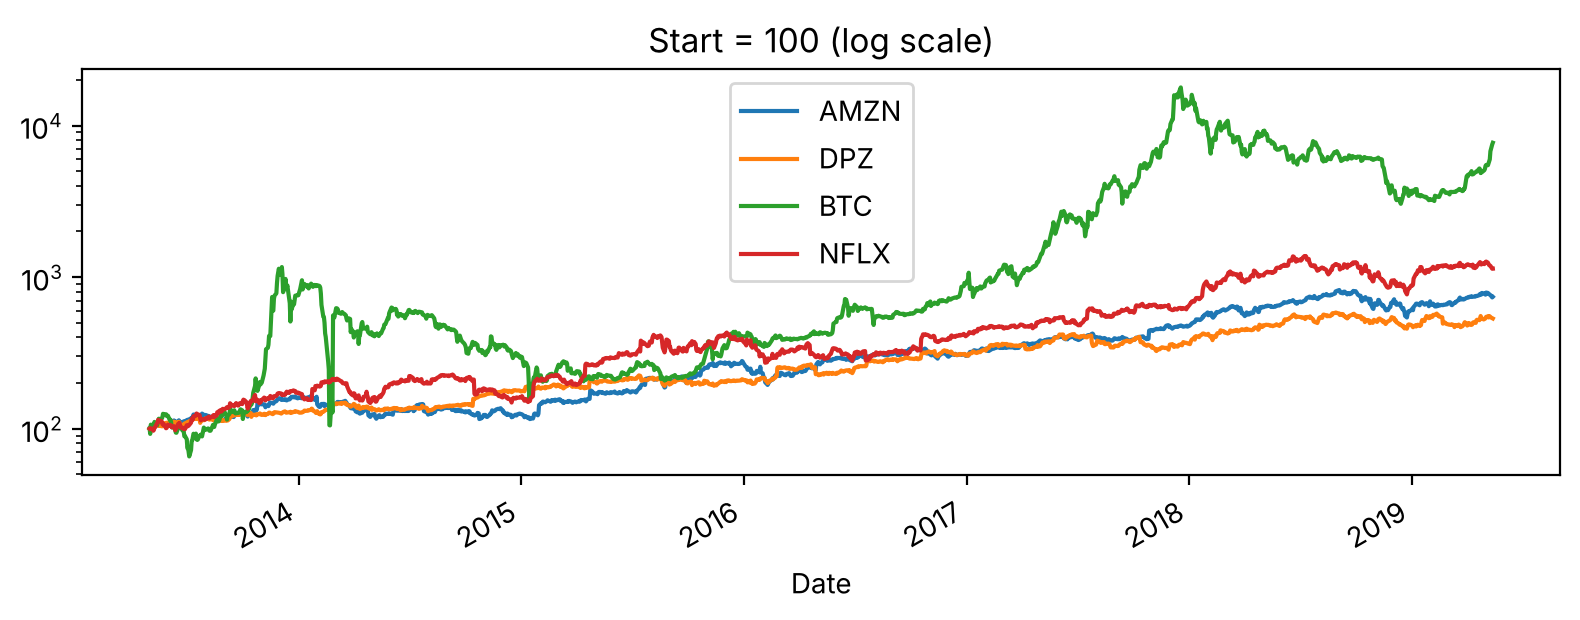

In [4]:
import matplotlib.pyplot as plt
(prices / prices.iloc[0] * 100).plot(logy=True, figsize=(8, 3.2), title='Start = 100 (log scale)'); plt.tight_layout(); plt.show()

In [5]:
international_portfolio_data = load('international_portfolio_data.csv', index_col=0)
international_portfolio_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2070 entries, 0 to 2069
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   real_date  2070 non-null   str    
 1   DOW        1425 non-null   float64
 2   VIX        1425 non-null   float64
 3   BTC        1851 non-null   float64
 4   ETH        1851 non-null   float64
 5   kospi      1391 non-null   str    
 6   vkospi     1391 non-null   float64
 7   gold       1391 non-null   str    
 8   dol        1391 non-null   str    
 9   DOW1       1116 non-null   float64
 10  VIX1       1116 non-null   str    
 11  BTC1       1849 non-null   float64
 12  ETH1       1849 non-null   float64
 13  kospi1     1068 non-null   float64
 14  vkospi1    1068 non-null   float64
 15  gold1      1068 non-null   float64
 16  dol1       1068 non-null   float64
 17  corona     2070 non-null   int64  
dtypes: float64(12), int64(1), str(5)
memory usage: 291.2 KB


In [6]:
# 숫자여야 할 열이 글자(object)로 읽혔어요 — '2,326.17'처럼 쉼표가 들어 있기 때문
ip = international_portfolio_data.copy()
for c in ['kospi', 'gold', 'dol', 'VIX1']:
    ip[c] = pd.to_numeric(ip[c].astype(str).str.replace(',', ''), errors='coerce')
ip[['kospi', 'gold', 'dol']].describe().round(1)

,kospi,gold,dol
count,1391.0,1391.0,1391.0
mean,2139.7,48861.3,1172.8
std,185.8,7737.2,50.0
min,1457.6,39900.0,1072.0
25%,2009.1,44455.0,1139.2
50%,2088.6,46000.0,1160.4
75%,2273.2,48850.0,1211.4
max,2598.2,80100.0,1338.8


In [7]:
# 빈 값이 많은 이유: 주말·휴장일에는 주식시장 값이 없고 코인 값만 있어요
ip['요일'] = pd.to_datetime(ip['real_date']).dt.day_name()
ip.groupby('요일')['kospi'].apply(lambda s: s.isna().mean()).round(2)

요일
Friday       0.06
Monday       0.06
Saturday     1.00
Sunday       1.00
Thursday     0.05
Tuesday      0.06
Wednesday    0.06
Name: kospi, dtype: float64

In [8]:
new_portfolio_data = load('new_portfolio_data.csv')
print(new_portfolio_data.shape, new_portfolio_data['Date'].iloc[0], '→', new_portfolio_data['Date'].iloc[-1])

(2468, 5) 2012-01-03 → 2021-10-21
